# SMS Spam Collection — Simple Data Analysis Project
This notebook covers **Sections 4, 5 and 6** of the assignment. Run the cells **from top to bottom**. Tables and charts appear here and the required files are saved automatically.

## 1. Import libraries

In [1]:
import re
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, silhouette_score
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer

Path('figures').mkdir(exist_ok=True)
Path('outputs').mkdir(exist_ok=True)

## 2. Understand the dataset
Each row is **one SMS message**. `text` is the text column; `label` is its category (ham or spam). Numerical columns will be created below.

In [2]:
df = pd.read_csv('data/SMSSpamCollection', sep='\t', header=None, names=['label', 'text'])
print('Shape:', df.shape)
display(df.head())
print('Columns:', df.columns.tolist())
print('Types:')
display(df.dtypes)
df.info()
display(df.describe(include='all'))

Shape: (5572, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Columns: ['label', 'text']
Types:


label    object
text     object
dtype: object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   5572 non-null   object
 1   text    5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


,label,text
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30


## 3. Missing values, duplicates and cleaning
Remove duplicate rows so identical SMS messages do not appear in both the training and test sets. Drop missing or empty messages because they cannot be classified from text.

In [3]:
print('Missing values:')
display(df.isna().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Before:', df.shape)
df = df.drop_duplicates().dropna(subset=['label', 'text']).copy()
df = df[df['text'].str.strip() != ''].reset_index(drop=True)
print('After:', df.shape)

Missing values:


label    0
text     0
dtype: int64

Duplicate rows: 403
Before: (5572, 2)
After: (5169, 2)


## 4. Select data using loc and iloc

In [4]:
display(df.loc[df['label'] == 'spam', ['label', 'text']].head())
display(df.iloc[:5, :2])
display(df.iloc[np.r_[0:3, 8:10], np.r_[0, 1]])

,label,text
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
5,spam,FreeMsg Hey there darling it's been 3 week's n...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...
11,spam,"SIX chances to win CASH! From 100 to 20,000 po..."


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


## 5. Clean SMS text and create features
Keep `text` unchanged; create `cleaned_text`. Convert to lowercase, replace URLs and numbers, remove punctuation and extra spaces. Additional transformations: encode the label, bin messages by length and normalize character count.

In [5]:
def clean_message(text):
    text = str(text).lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' urltoken ', text)
    text = re.sub(r'\d+', ' numtoken ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    return ' '.join(text.split())

df['cleaned_text'] = df['text'].apply(clean_message)
df['tokens'] = df['cleaned_text'].str.split()
df['char_count'] = df['text'].str.len()
df['word_count'] = df['tokens'].str.len()
df['unique_word_count'] = df['tokens'].apply(lambda x: len(set(x)))
df['avg_word_length'] = df['tokens'].apply(lambda x: sum(map(len, x)) / len(x) if x else 0)
df['label_encoded'] = df['label'].map({'ham': 0, 'spam': 1})
df['length_bin'] = pd.cut(df['char_count'], bins=[0, 50, 120, float('inf')], labels=['short', 'medium', 'long'])
df['normalized_char_count'] = df['char_count'] / df['char_count'].max()
display(df[['label','text','cleaned_text','char_count','word_count','length_bin']].head())
display(df[['char_count','word_count','unique_word_count','avg_word_length']].describe())

,label,text,cleaned_text,char_count,word_count,length_bin
0,ham,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...,111,20,medium
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif u oni,29,6,short
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in numtoken a wkly comp to win fa c...,155,36,long
3,ham,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say,49,11,short
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...,61,14,medium


,char_count,word_count,unique_word_count,avg_word_length
count,5169.000000,5169.000000,5169.000000,5169.000000
mean,79.344554,16.251693,14.327723,3.902709
std,58.437457,11.794811,8.858197,0.767300
min,2.000000,0.000000,0.000000,0.000000
25%,36.000000,8.000000,7.000000,3.400000
50%,61.000000,13.000000,12.000000,3.800000
75%,119.000000,24.000000,20.000000,4.321429
max,910.000000,190.000000,94.000000,10.500000


## 6. Sampling: random, stratified, and cluster
**Random:** draw individual messages randomly. **Stratified:** maintain the ham/spam ratio. **Cluster:** randomly choose entire blocks of 100 messages (a demonstration of cluster sampling, because the dataset has no natural group ID).

Sample sizes: {'Original': 5169, 'Random': 1000, 'Stratified': 1000, 'Cluster': 1000}


label,ham,spam
Original,87.37,12.63
Random,86.20,13.80
Stratified,87.40,12.60
Cluster,87.50,12.50


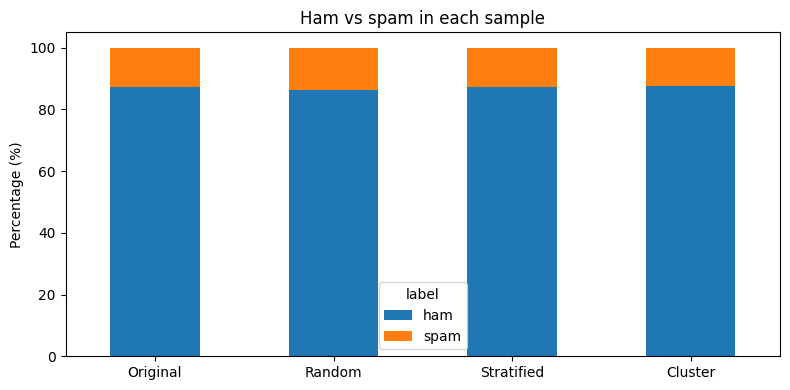

In [6]:
random_sample = df.sample(n=1000, random_state=42)
stratified_sample, _ = train_test_split(df, train_size=1000, stratify=df['label'], random_state=42)
blocks = df.index // 100
chosen_blocks = pd.Series(blocks.unique()).sample(n=10, random_state=42)
cluster_sample = df[blocks.isin(chosen_blocks)]

samples = {'Original': df, 'Random': random_sample, 'Stratified': stratified_sample, 'Cluster': cluster_sample}
distribution = pd.DataFrame({name: data['label'].value_counts(normalize=True) * 100 for name, data in samples.items()}).T
print('Sample sizes:', {name: len(data) for name, data in samples.items()})
display(distribution.round(2))
distribution.plot(kind='bar', stacked=True, figsize=(8, 4))
plt.ylabel('Percentage (%)')
plt.title('Ham vs spam in each sample')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('figures/sampling_distribution.png')
plt.show()

Stratified sampling preserves the original proportions most closely. Random sampling can shift them slightly by chance. Cluster sampling may differ more because it selects whole groups; here groups are artificial 100-row blocks, so conclusions depend on row order.

## 7. Correlation heatmap
Correlation measures how strongly numerical features change together. It **does not prove causation**, especially because these features are derived from the same SMS text.

,char_count,word_count,unique_word_count,avg_word_length
char_count,1.00,0.98,0.96,0.22
word_count,0.98,1.00,0.97,0.10
unique_word_count,0.96,0.97,1.00,0.09
avg_word_length,0.22,0.10,0.09,1.00


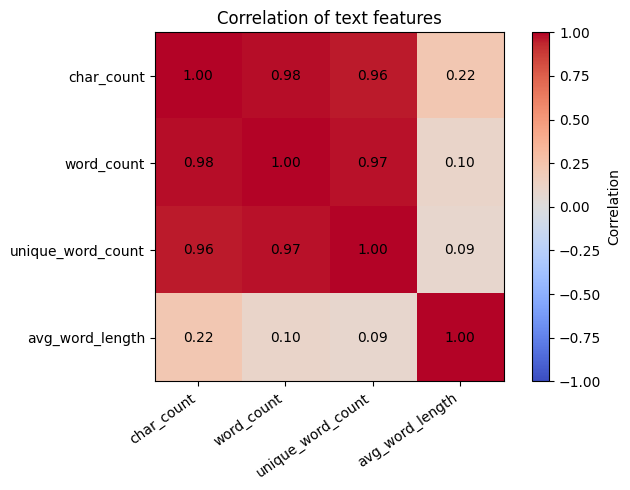

Word count vs unique words: 0.97


In [7]:
numeric_features = ['char_count','word_count','unique_word_count','avg_word_length']
correlation = df[numeric_features].corr()
display(correlation.round(2))
plt.figure(figsize=(7, 5))
plt.imshow(correlation, vmin=-1, vmax=1, cmap='coolwarm')
plt.colorbar(label='Correlation')
plt.xticks(range(4), numeric_features, rotation=35, ha='right')
plt.yticks(range(4), numeric_features)
for i in range(4):
    for j in range(4):
        plt.text(j, i, f'{correlation.iloc[i,j]:.2f}', ha='center', va='center')
plt.title('Correlation of text features')
plt.tight_layout()
plt.savefig('figures/correlation_heatmap.png')
plt.show()
print('Word count vs unique words:', round(correlation.loc['word_count','unique_word_count'], 2))

## 8. Word frequencies and token statistics

Total tokens: 84005
Unique words: 7742
Average words per SMS: 16.25
Top 20, including stopwords:


,word,count
0,numtoken,3928
1,i,2860
2,you,2150
3,to,2080
4,a,1325
5,the,1249
6,u,1090
7,and,930
8,in,835
9,is,800


Top 20, excluding stopwords:


,word,count
0,numtoken,3928
1,just,350
2,ur,322
3,gt,288
4,lt,287
5,ok,261
6,free,253
7,know,244
8,ll,237
9,like,236


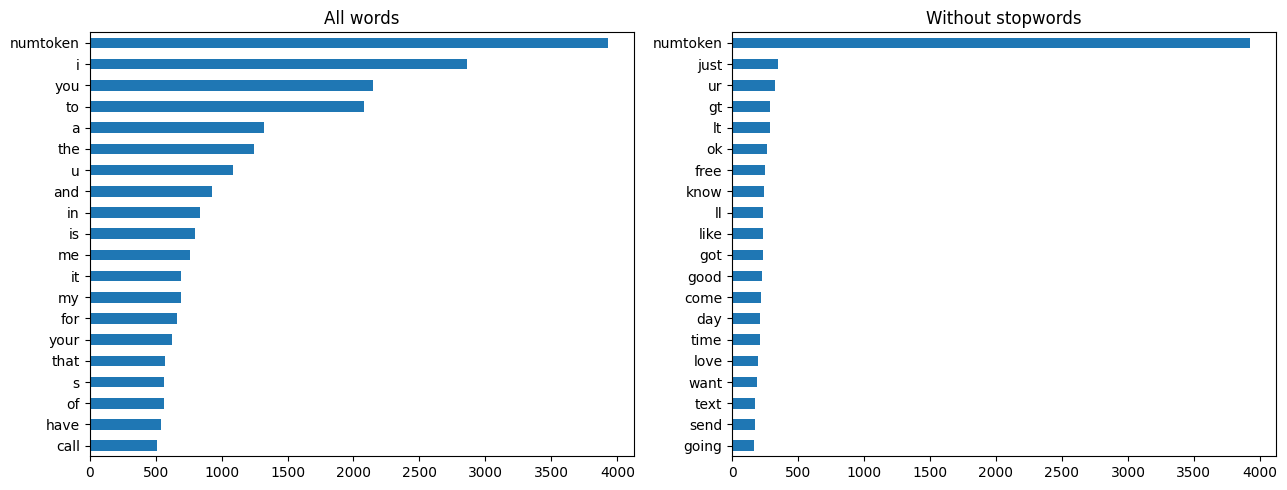

In [8]:
words = [word for message in df['tokens'] for word in message]
word_counts = Counter(words)
filtered_words = Counter(w for w in words if w not in ENGLISH_STOP_WORDS and len(w) > 1)
print('Total tokens:', len(words))
print('Unique words:', len(word_counts))
print('Average words per SMS:', round(df['word_count'].mean(), 2))
print('Top 20, including stopwords:')
display(pd.DataFrame(word_counts.most_common(20), columns=['word','count']))
print('Top 20, excluding stopwords:')
display(pd.DataFrame(filtered_words.most_common(20), columns=['word','count']))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, counts, heading in zip(axes, [word_counts, filtered_words], ['All words', 'Without stopwords']):
    top = pd.Series(dict(counts.most_common(20)))
    top.sort_values().plot.barh(ax=ax)
    ax.set_title(heading)
plt.tight_layout()
plt.savefig('figures/word_frequency.png')
plt.show()

## 9. Compare ham and spam groups

,char_count,word_count
label,,
ham,70.91,14.74
spam,137.70,26.74


ham top 10 words: [('numtoken', 1125), ('gt', 288), ('lt', 287), ('just', 282), ('ok', 256), ('ll', 233), ('got', 228), ('know', 226), ('like', 224), ('good', 217)]
spam top 10 words: [('numtoken', 2803), ('free', 197), ('txt', 138), ('ur', 119), ('stop', 116), ('mobile', 111), ('text', 108), ('claim', 96), ('reply', 96), ('urltoken', 90)]


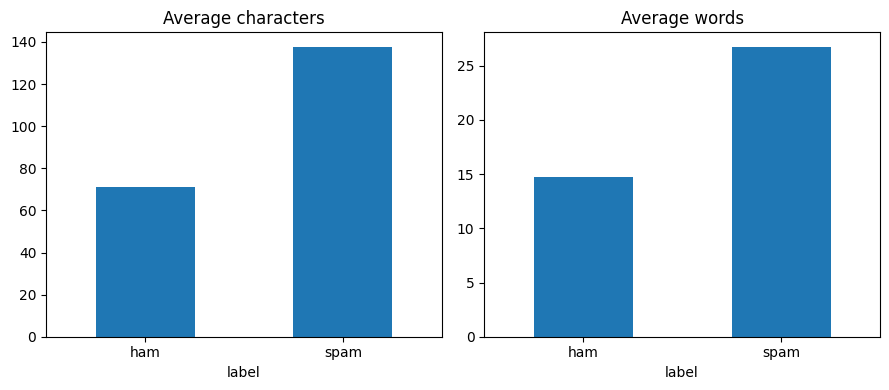

In [9]:
group_stats = df.groupby('label')[['char_count','word_count']].mean()
display(group_stats.round(2))
for label in ['ham', 'spam']:
    group_words = [w for tokens in df.loc[df['label'] == label, 'tokens'] for w in tokens if w not in ENGLISH_STOP_WORDS and len(w) > 1]
    print(label, 'top 10 words:', Counter(group_words).most_common(10))
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
group_stats['char_count'].plot.bar(ax=axes[0], title='Average characters', rot=0)
group_stats['word_count'].plot.bar(ax=axes[1], title='Average words', rot=0)
plt.tight_layout()
plt.savefig('figures/group_comparison.png')
plt.show()

## 10. Supervised classification with TF-IDF
Split 80/20 using stratification, fit TF-IDF on training messages only, and train a balanced Logistic Regression classifier to account for the smaller spam class.

Accuracy: 0.9816
              precision    recall  f1-score   support

         ham     0.9911    0.9878    0.9895       903
        spam     0.9179    0.9389    0.9283       131

    accuracy                         0.9816      1034
   macro avg     0.9545    0.9634    0.9589      1034
weighted avg     0.9818    0.9816    0.9817      1034



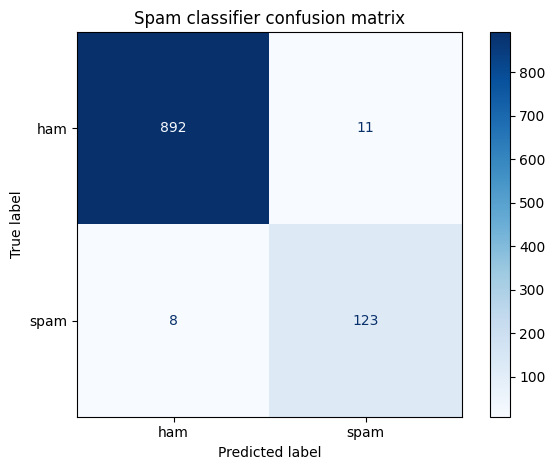

471

In [10]:
X_train, X_test, y_train, y_test = train_test_split(df['cleaned_text'], df['label'], test_size=0.2, stratify=df['label'], random_state=42)
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
model.fit(X_train_tfidf, y_train)
predictions = model.predict(X_test_tfidf)
report = classification_report(y_test, predictions, digits=4)
print('Accuracy:', round(accuracy_score(y_test, predictions), 4))
print(report)
ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=['ham','spam'], cmap='Blues')
plt.title('Spam classifier confusion matrix')
plt.tight_layout()
plt.savefig('figures/confusion_matrix.png')
plt.show()
Path('outputs/model_metrics.txt').write_text('Accuracy: ' + str(round(accuracy_score(y_test, predictions), 4)) + '\n' + report + '\nConfusion matrix [ham, spam]:\n' + str(confusion_matrix(y_test, predictions, labels=['ham','spam'])) + '\nLimitation: SMS language can change over time; the dataset is historical.\n')

## 11. K-Means clustering
Use **k=2** because the dataset has two broad known message categories, although clusters are not required to match them. Reduce TF-IDF to 50 dimensions to make clustering faster. Silhouette score is calculated on a random subset for speed.

In [11]:
cluster_tfidf = TfidfVectorizer(stop_words='english', min_df=3, max_features=3500)
X = cluster_tfidf.fit_transform(df['cleaned_text'])
X_small = TruncatedSVD(n_components=50, random_state=42).fit_transform(X)
X_small = Normalizer().fit_transform(X_small)
kmeans = MiniBatchKMeans(n_clusters=2, random_state=42, n_init=10, batch_size=512)
df['cluster'] = kmeans.fit_predict(X_small)
cluster_sizes = df['cluster'].value_counts().sort_index()
score = silhouette_score(X_small, df['cluster'], sample_size=1000, random_state=42)
comparison = pd.crosstab(df['cluster'], df['label'], normalize='index')
print('Cluster sizes:')
display(cluster_sizes)
print('Silhouette score:', round(score, 4))
print('Known label percentages per cluster:')
display((comparison * 100).round(2))
summary_lines = ['K-Means with k=2 (50-dimensional reduced TF-IDF)', f'Silhouette score: {score:.4f}', 'Cluster sizes: ' + str(cluster_sizes.to_dict()), 'Label ratios by cluster: ' + comparison.round(3).to_string()]
for cluster_number in range(2):
    subset = df[df['cluster'] == cluster_number]
    terms = Counter(w for tokens in subset['tokens'] for w in tokens if w not in ENGLISH_STOP_WORDS and len(w)>2).most_common(10)
    print(f'Cluster {cluster_number} most frequent words:', terms)
    summary_lines.append(f'Cluster {cluster_number} top terms: {terms}')
    summary_lines.append(f'Cluster {cluster_number} mostly contains {comparison.loc[cluster_number].idxmax()} messages, but clusters and labels are different concepts.')
Path('outputs/cluster_summary.txt').write_text('\n'.join(summary_lines))

Cluster sizes:


cluster
0    4121
1    1048
Name: count, dtype: int64

Silhouette score: 0.0911
Known label percentages per cluster:


label,ham,spam
cluster,,
0,98.62,1.38
1,43.13,56.87


Cluster 0 most frequent words: [('numtoken', 304), ('just', 268), ('know', 218), ('like', 210), ('good', 205), ('come', 202), ('got', 199), ('time', 181), ('day', 180), ('love', 173)]
Cluster 1 most frequent words: [('numtoken', 3624), ('free', 181), ('txt', 144), ('stop', 114), ('mobile', 99), ('text', 94), ('claim', 94), ('reply', 94), ('prize', 82), ('just', 82)]


746

## 12. Five evidence-based insights

In [12]:
print(f"1. Ham messages make up {(df['label']=='ham').mean():.1%} of messages, so the classes are imbalanced; stratified splitting is important.")
print(f"2. Average length: ham {group_stats.loc['ham','char_count']:.1f} characters, spam {group_stats.loc['spam','char_count']:.1f}; length can help distinguish the groups.")
print(f"3. Correlation between word count and unique word count is {correlation.loc['word_count','unique_word_count']:.2f}; longer messages generally contain more different words, but correlation is not causation.")
print(f"4. Test accuracy is {accuracy_score(y_test,predictions):.1%}; the classifier is useful, but false positives and false negatives remain important.")
print(f"5. K-Means silhouette score is {score:.3f}; this measures how separate the text clusters are, not how correctly they identify spam.")

1. Ham messages make up 87.4% of messages, so the classes are imbalanced; stratified splitting is important.
2. Average length: ham 70.9 characters, spam 137.7; length can help distinguish the groups.
3. Correlation between word count and unique word count is 0.97; longer messages generally contain more different words, but correlation is not causation.
4. Test accuracy is 98.2%; the classifier is useful, but false positives and false negatives remain important.
5. K-Means silhouette score is 0.091; this measures how separate the text clusters are, not how correctly they identify spam.


## 13. Save cleaned dataset
Only **one CSV** is saved. The temporary Python `tokens` list is excluded; the original text remains unchanged.

In [13]:
df.drop(columns=['tokens']).to_csv('cleaned_data.csv', index=False)
print('Saved cleaned_data.csv, four analysis charts, confusion matrix, and two text reports.')

Saved cleaned_data.csv, four analysis charts, confusion matrix, and two text reports.
